# Module 3 — Decision Tree Classification
### Parent–Young Adult Independence in the United States


## 1. Load the dataset and define the supervised task

In [1]:
import os
import shutil
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score)

DATA_URL = (
    "https://raw.githubusercontent.com/swejal22/"
    "parent-child-independence-project/main/"
    "pew_young_adults_clean_numeric.csv"
)
OUTPUT_DIR = Path("dt_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

df = pd.read_csv(DATA_URL)
features = [
    "received_financial_help", "lives_with_parents",
    "parent_involvement_level", "communication_satisfaction",
    "employment_status", "age_group"
]
target = "financial_independence"

required_cols = features + [target]
missing_cols = [name for name in required_cols if name not in df.columns]
if missing_cols:
    raise ValueError(f"Required columns not found in dataset: {missing_cols}")

model_df = df[required_cols].dropna().copy()
X = model_df[features].copy()
y = model_df[target].astype(int)
class_labels = sorted(y.unique().tolist())

print("Original dataset:", df.shape)
print("Cleaned labeled dataset:", model_df.shape)
print("Removed records:", len(df) - len(model_df))
print("Class distribution:")
print(y.value_counts().sort_index())
print("\nLabeled sample:")
display(model_df.head())

Original dataset: (1495, 30)
Cleaned labeled dataset: (1478, 7)
Removed records: 17
Class distribution:
financial_independence
1    786
2    338
3    163
4    117
5     74
Name: count, dtype: int64

Labeled sample:


,received_financial_help,lives_with_parents,parent_involvement_level,communication_satisfaction,employment_status,age_group,financial_independence
0,1.0,1.0,1.0,3.0,2.0,1,2.0
1,2.0,3.0,3.0,3.0,1.0,1,1.0
2,2.0,3.0,3.0,3.0,2.0,2,1.0
3,2.0,3.0,3.0,2.0,1.0,1,4.0
4,1.0,3.0,3.0,1.0,1.0,2,2.0


## 2. Train/test split and categorical encoding



In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

try:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:  # Older scikit-learn
    encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

X_train_array = encoder.fit_transform(X_train)
X_test_array = encoder.transform(X_test)
encoded_names = encoder.get_feature_names_out(features)

X_train_encoded = pd.DataFrame(X_train_array, columns=encoded_names, index=X_train.index)
X_test_encoded = pd.DataFrame(X_test_array, columns=encoded_names, index=X_test.index)

assert len(set(X_train.index).intersection(set(X_test.index))) == 0
assert X_train_encoded.columns.tolist() == X_test_encoded.columns.tolist()

print(f"Training records: {len(X_train)}")
print(f"Testing records: {len(X_test)}")
print(f"Encoded features: {X_train_encoded.shape[1]}")
print(f"Overlapping indices: {len(set(X_train.index) & set(X_test.index))}")
display(X_train_encoded.head())

Training records: 1182
Testing records: 296
Encoded features: 18
Overlapping indices: 0


,received_financial_help_1.0,received_financial_help_2.0,lives_with_parents_1.0,lives_with_parents_2.0,lives_with_parents_3.0,parent_involvement_level_1.0,parent_involvement_level_2.0,parent_involvement_level_3.0,communication_satisfaction_1.0,communication_satisfaction_2.0,communication_satisfaction_3.0,employment_status_1.0,employment_status_2.0,employment_status_3.0,employment_status_4.0,employment_status_5.0,age_group_1,age_group_2
714,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
237,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
37,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
689,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
1302,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


## 3. Export labeled, training, and testing datasets

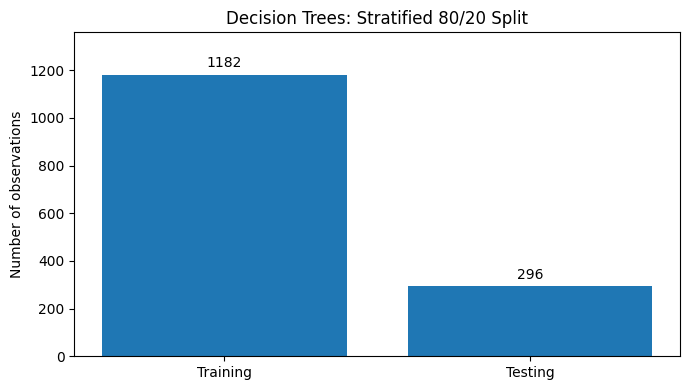

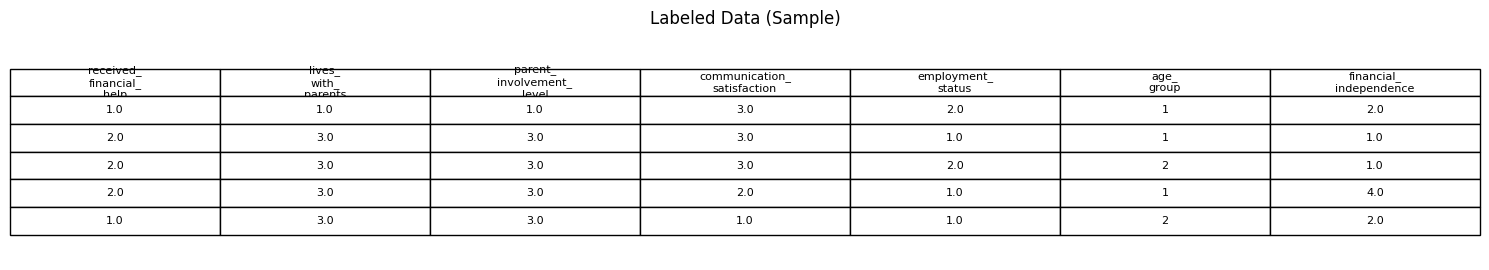

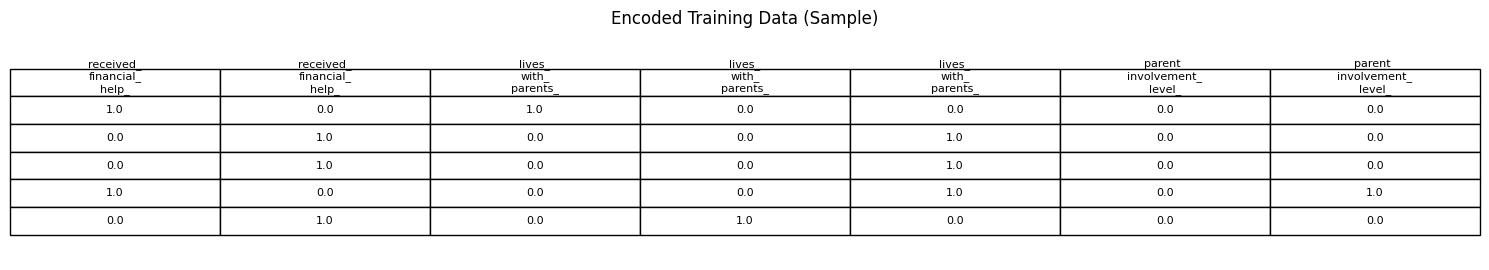

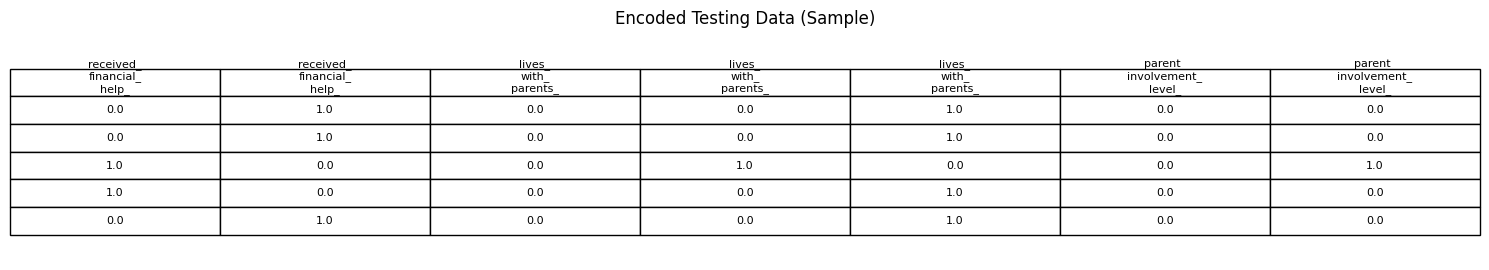

In [4]:
model_df.to_csv(OUTPUT_DIR / "dt_labeled_data.csv", index=False)
train_export = X_train_encoded.copy()
train_export[target] = y_train
test_export = X_test_encoded.copy()
test_export[target] = y_test
train_export.to_csv(OUTPUT_DIR / "dt_training_data.csv", index=False)
test_export.to_csv(OUTPUT_DIR / "dt_testing_data.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 4))
values = [len(X_train), len(X_test)]
bars = ax.bar(["Training", "Testing"], values)
ax.bar_label(bars, padding=3)
ax.set_ylabel("Number of observations")
ax.set_title("Decision Trees: Stratified 80/20 Split")
ax.set_ylim(0, max(values) * 1.15)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "dt_train_test_split.png", dpi=180, bbox_inches="tight")
plt.show()

# Save static screenshots of actual sample values to meet the image requirement.
def save_sample_table(frame, title, filename, max_columns=7):
    sample = frame.head(5).iloc[:, :max_columns].copy()
    sample.columns = [str(c).replace("_", "_\n") for c in sample.columns]
    fig, ax = plt.subplots(figsize=(15, 2.8))
    ax.axis("off")
    tbl = ax.table(cellText=sample.astype(str).values,
                   colLabels=sample.columns,
                   loc="center", cellLoc="center")
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(8)
    tbl.scale(1, 1.65)
    ax.set_title(title, fontsize=12, pad=14)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / filename, dpi=180, bbox_inches="tight")
    plt.show()

save_sample_table(model_df, "Labeled Data (Sample)", "dt_labeled_sample.png")

save_sample_table(train_export, "Encoded Training Data (Sample)", "dt_training_sample.png")
save_sample_table(test_export, "Encoded Testing Data (Sample)", "dt_testing_sample.png")

## 4. Worked example: Gini, entropy, and information gain

A small **hypothetical binary classification example** illustrates how to assess a candidate split. It is NOT a result from our survey data. Parent: 5 of class A and 5 of class B. Left child: 3 A / 1 B. Right child: 2 A / 4 B. Compute parent impurity, weighted child impurity, and the reduction (gain).

In [5]:
def gini(counts):
    p = np.asarray(counts, dtype=float)
    p = p / p.sum()
    return 1 - np.sum(p ** 2)

def entropy(counts):
    p = np.asarray(counts, dtype=float)
    p = p[p > 0] / np.sum(p)
    return -np.sum(p * np.log2(p))

parent = [5, 5]
left, right = [3, 1], [2, 4]
n_left, n_right = sum(left), sum(right)
total = n_left + n_right
wg = (n_left/total)*gini(left) + (n_right/total)*gini(right)
we = (n_left/total)*entropy(left) + (n_right/total)*entropy(right)
print(f"Parent Gini: {gini(parent):.4f}")
print(f"Weighted child Gini: {wg:.4f}")
print(f"Gini reduction: {gini(parent)-wg:.4f}")
print(f"Parent entropy: {entropy(parent):.4f} bits")
print(f"Weighted child entropy: {we:.4f} bits")
print(f"Information gain (entropy reduction): {entropy(parent)-we:.4f} bits")

Parent Gini: 0.5000
Weighted child Gini: 0.4167
Gini reduction: 0.0833
Parent entropy: 1.0000 bits
Weighted child entropy: 0.8755 bits
Information gain (entropy reduction): 0.1245 bits


## 5. Train three different Decision Trees

- **Tree 1:** Gini, max depth 3
- **Tree 2:** Gini, max depth 5
- **Tree 3:** Entropy, max depth 5

All use the same training/testing split. Different depths or split criteria can lead to different decision rules. Tree diagrams show fitted structure; test scores should determine whether a model generalizes well.

In [6]:
tree_configs = {
    "Tree 1 — Gini depth 3": dict(criterion="gini", max_depth=3),
    "Tree 2 — Gini depth 5": dict(criterion="gini", max_depth=5),
    "Tree 3 — Entropy depth 5": dict(criterion="entropy", max_depth=5)
}
models, predictions, report_rows = {}, {}, []

for number, (name, params) in enumerate(tree_configs.items(), start=1):
    model = DecisionTreeClassifier(random_state=42, **params)
    model.fit(X_train_encoded, y_train)
    predicted = model.predict(X_test_encoded)
    models[name] = model
    predictions[name] = predicted

    metrics = {
        "Tree": name,
        "Accuracy": accuracy_score(y_test, predicted),
        "Balanced accuracy": balanced_accuracy_score(y_test, predicted),
        "Macro F1": f1_score(y_test, predicted, average="macro", zero_division=0),
        "Actual depth": model.get_depth(),
        "Leaf nodes": model.get_n_leaves()
    }
    report_rows.append(metrics)

    print(f"\n{name}")
    print(f"Accuracy: {metrics['Accuracy']:.4f} ({metrics['Accuracy']:.2%})")
    print(f"Balanced accuracy: {metrics['Balanced accuracy']:.4f}")
    print(f"Macro F1: {metrics['Macro F1']:.4f}")
    print(classification_report(y_test, predicted, labels=class_labels, zero_division=0))

results = pd.DataFrame(report_rows)
results.to_csv(OUTPUT_DIR / "dt_model_comparison.csv", index=False)
print("\nModel comparison:")
display(results.round(4))


Tree 1 — Gini depth 3
Accuracy: 0.5845 (58.45%)
Balanced accuracy: 0.3597
Macro F1: 0.3497
              precision    recall  f1-score   support

           1       0.76      0.82      0.79       157
           2       0.38      0.47      0.42        68
           3       0.21      0.12      0.15        33
           4       0.39      0.39      0.39        23
           5       0.00      0.00      0.00        15

    accuracy                           0.58       296
   macro avg       0.35      0.36      0.35       296
weighted avg       0.54      0.58      0.56       296


Tree 2 — Gini depth 5
Accuracy: 0.5912 (59.12%)
Balanced accuracy: 0.3949
Macro F1: 0.4074
              precision    recall  f1-score   support

           1       0.76      0.82      0.79       157
           2       0.41      0.43      0.42        68
           3       0.26      0.24      0.25        33
           4       0.36      0.22      0.27        23
           5       0.36      0.27      0.31        15

 

,Tree,Accuracy,Balanced accuracy,Macro F1,Actual depth,Leaf nodes
0,Tree 1 — Gini depth 3,0.5845,0.3597,0.3497,3,8
1,Tree 2 — Gini depth 5,0.5912,0.3949,0.4074,5,32
2,Tree 3 — Entropy depth 5,0.5845,0.4183,0.3988,5,32


## 6. Plot and save all three decision trees

These are **three separately trained fitted trees**, not just different views of the same tree.

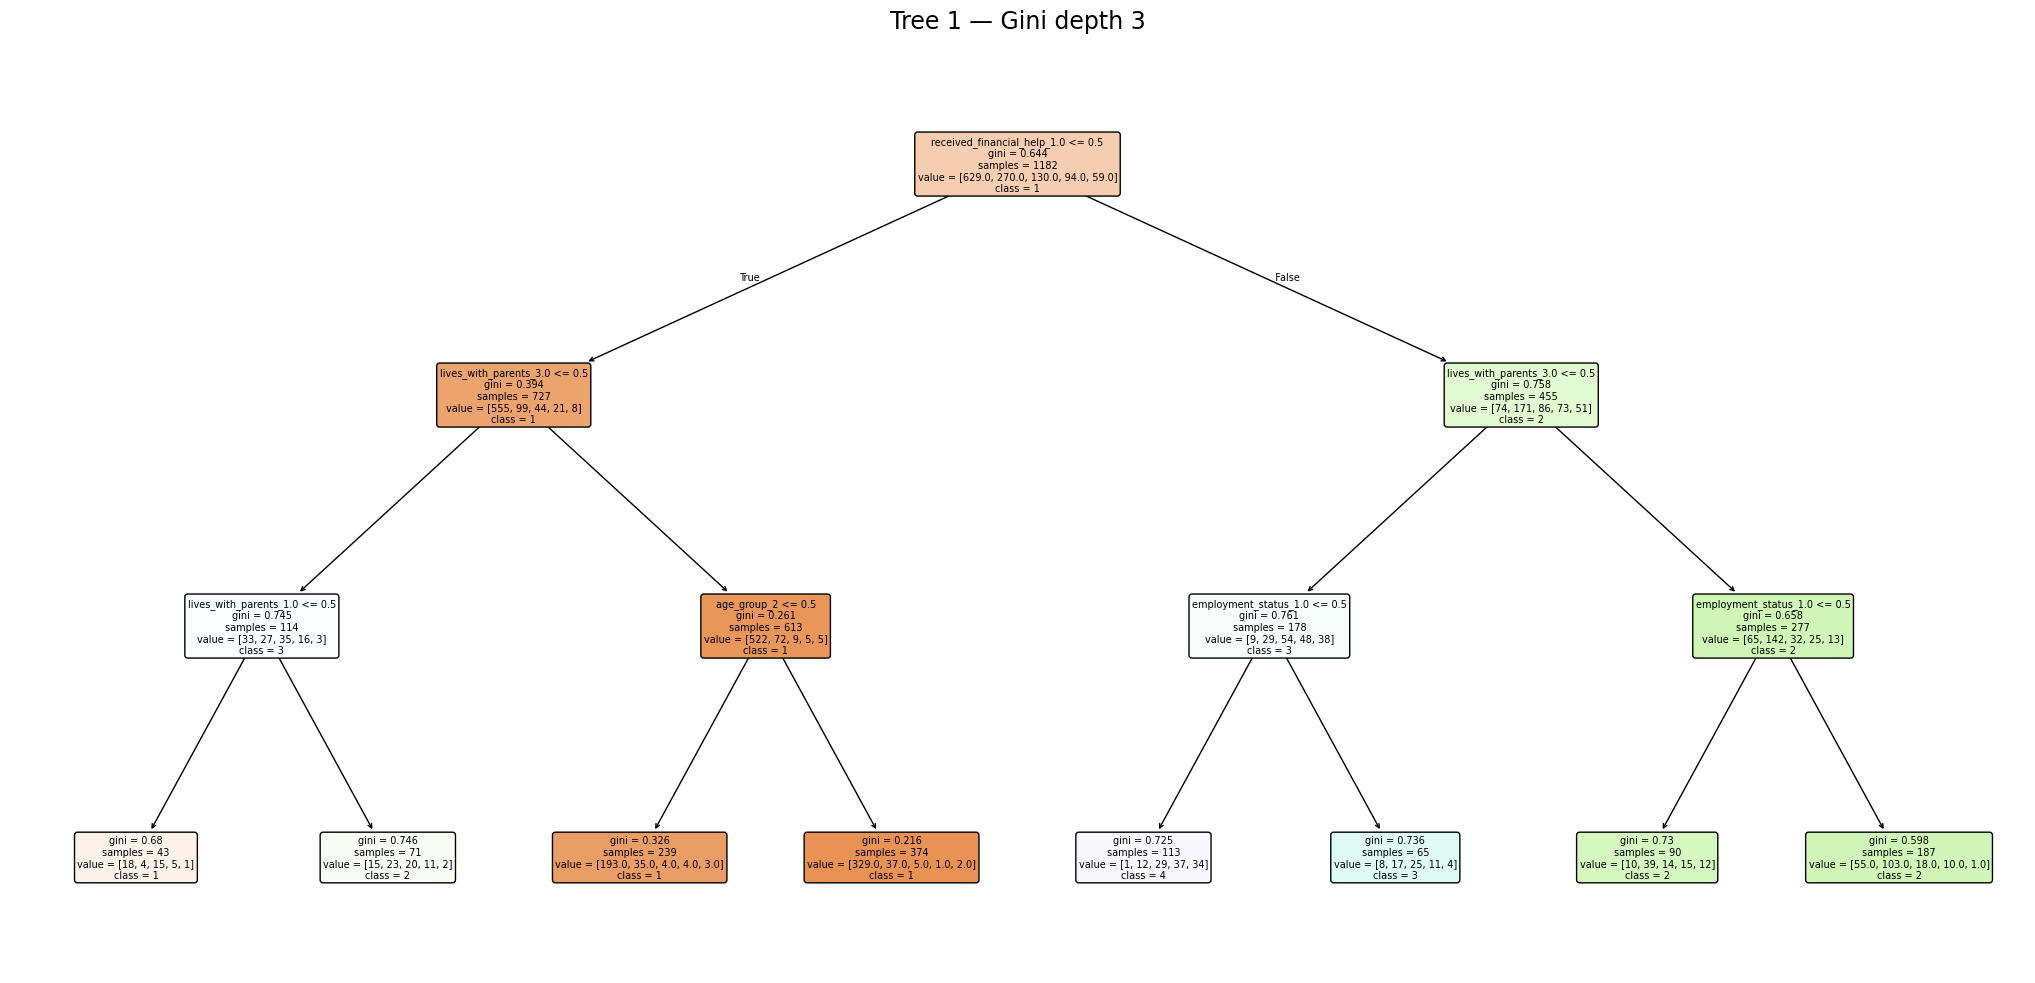

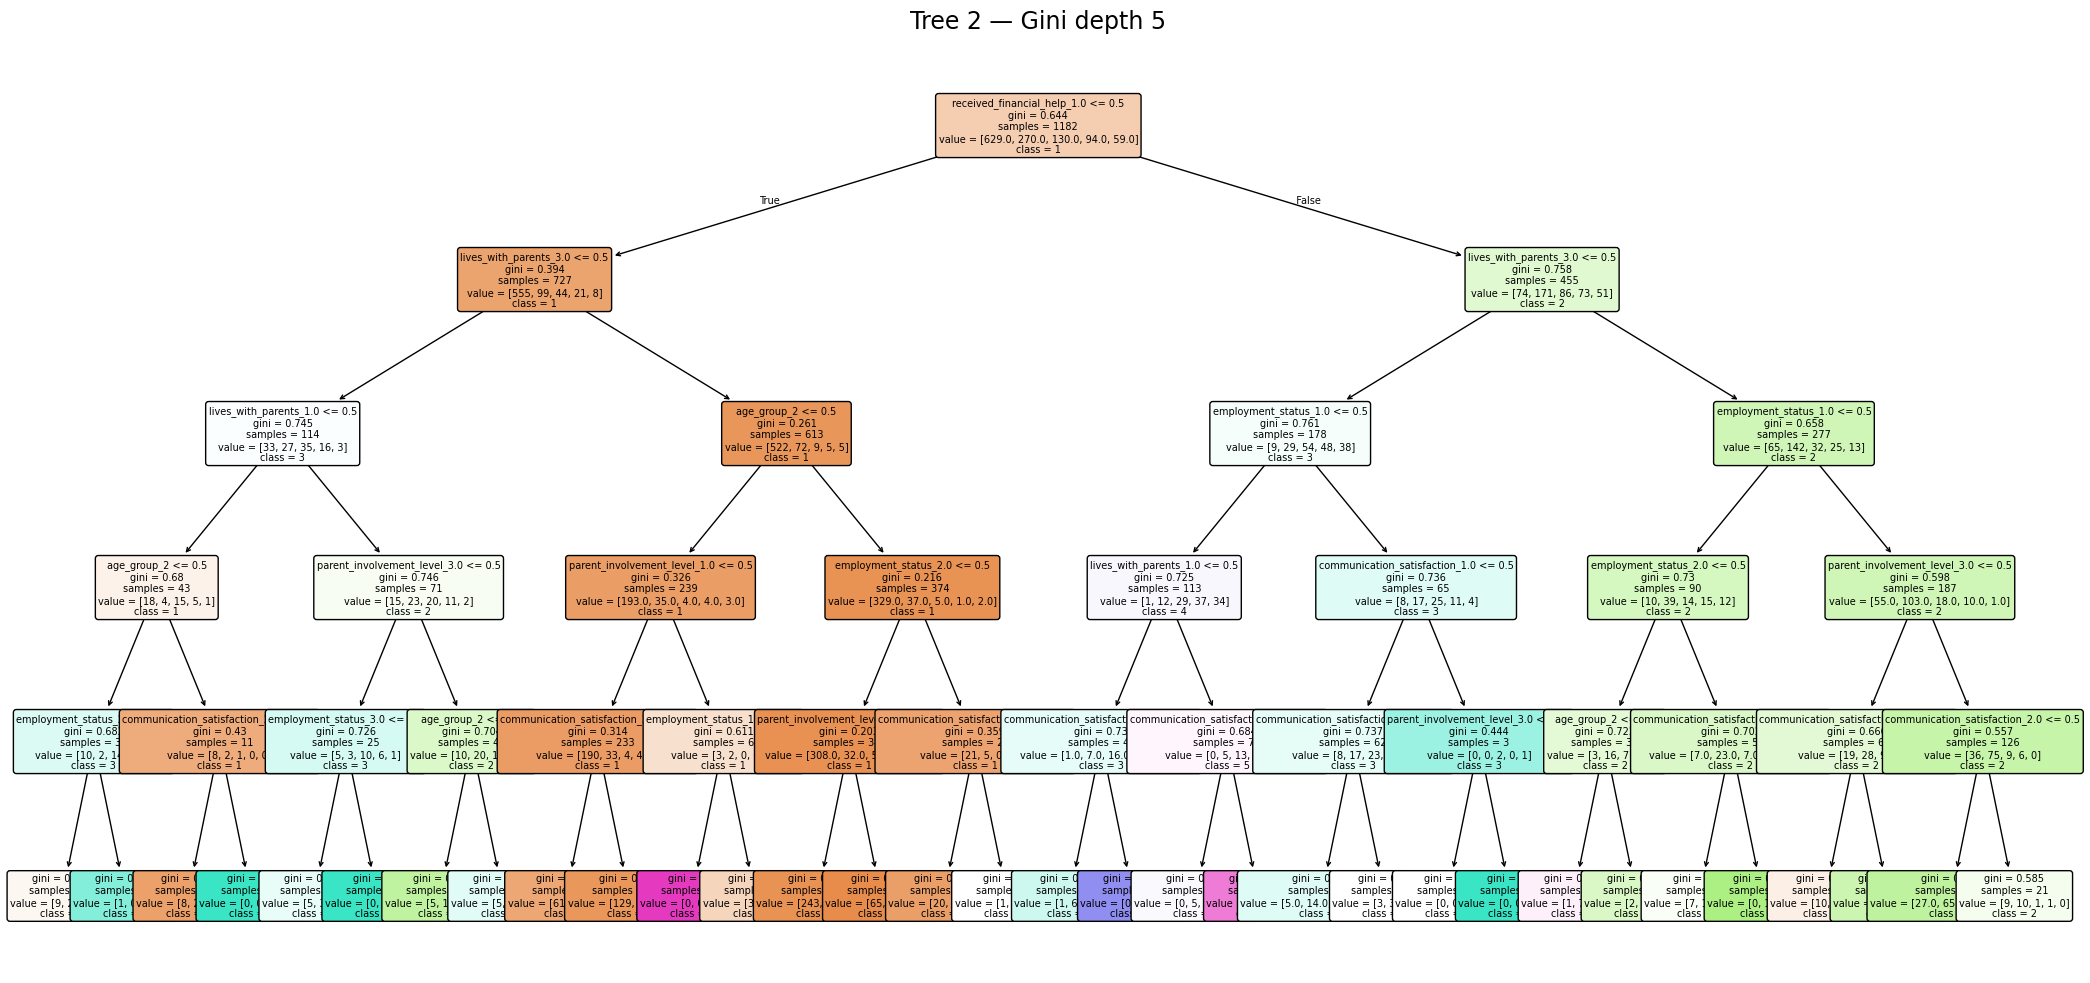

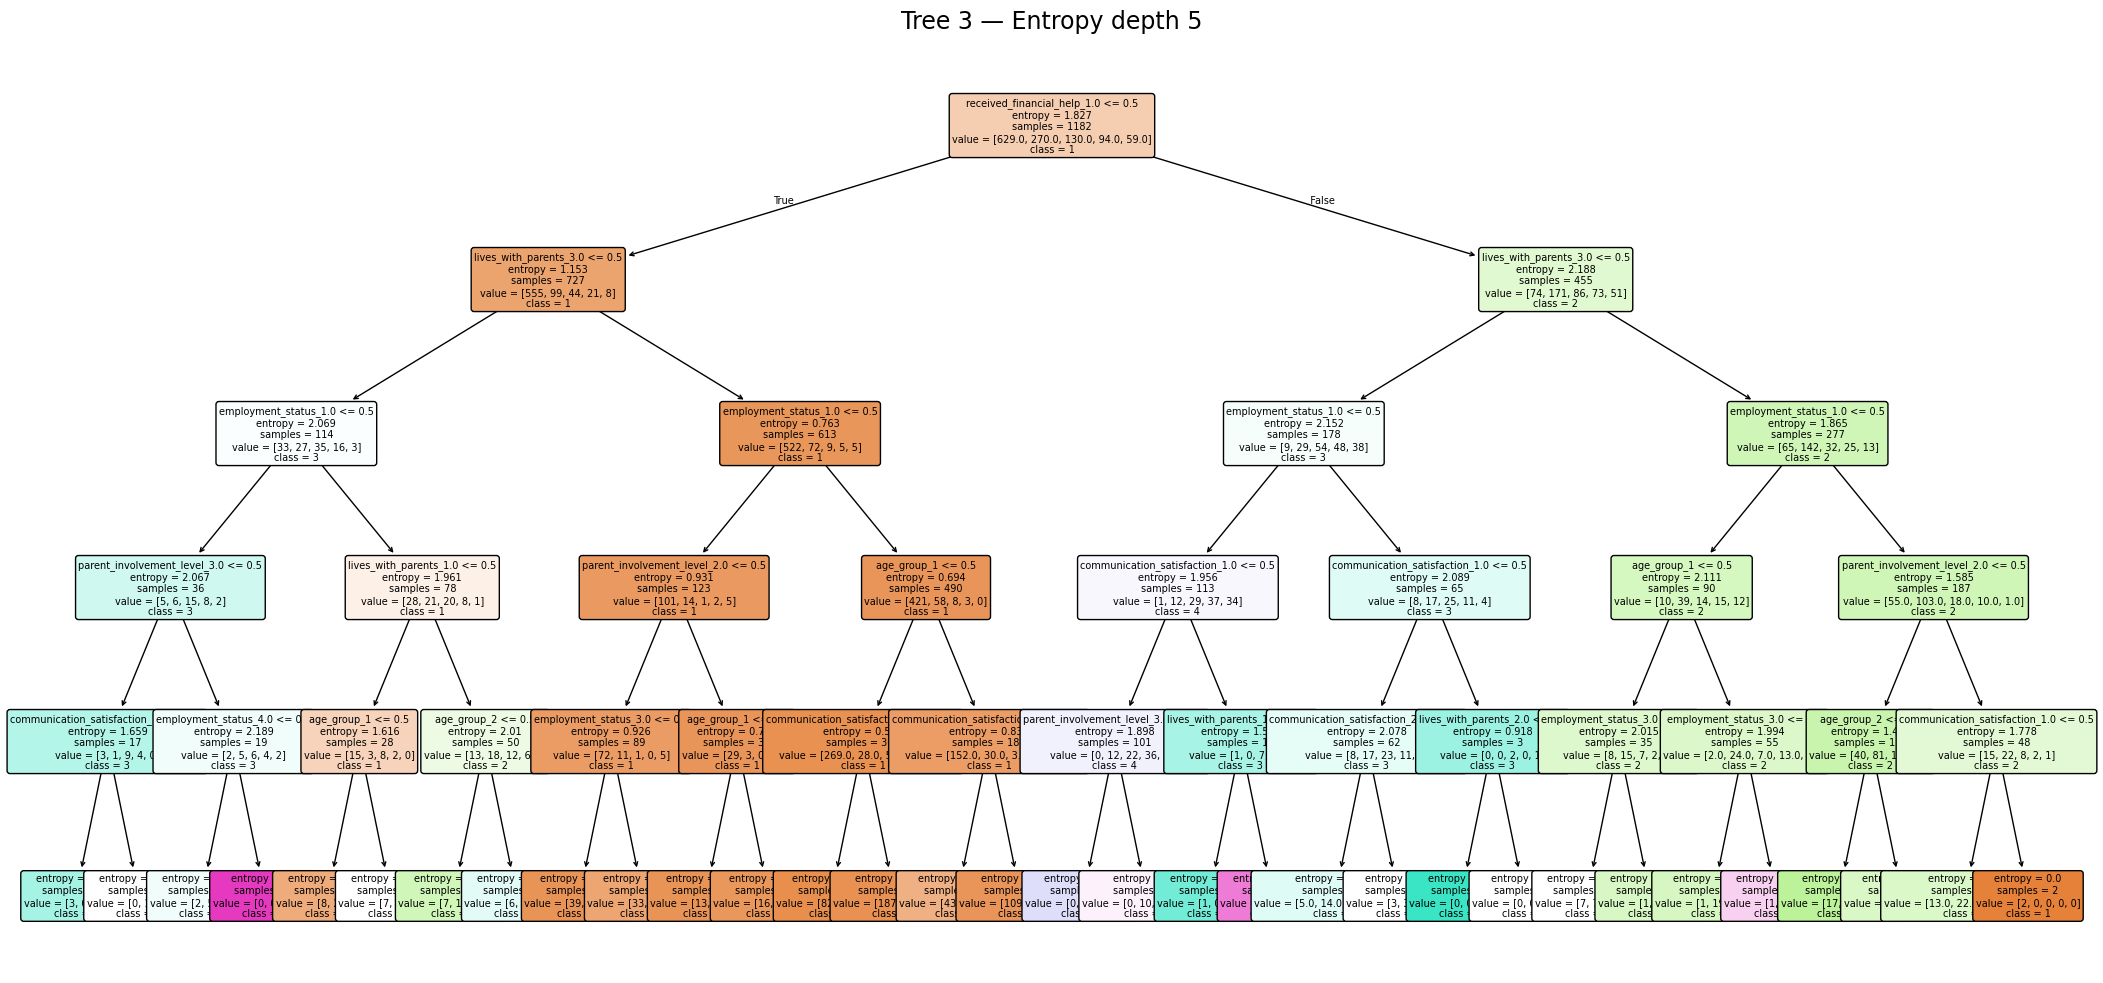

In [7]:
for number, (name, model) in enumerate(models.items(), start=1):
    fig, ax = plt.subplots(figsize=(26, 12))
    plot_tree(
        model,
        feature_names=X_train_encoded.columns.tolist(),
        class_names=[str(c) for c in model.classes_],
        filled=True, rounded=True, fontsize=7, ax=ax,
        impurity=True, proportion=False
    )
    ax.set_title(name, fontsize=17, pad=15)
    fig.savefig(OUTPUT_DIR / f"dt_tree_{number}.png", dpi=190, bbox_inches="tight")
    plt.show()

## 7. Confusion matrices and comparisons

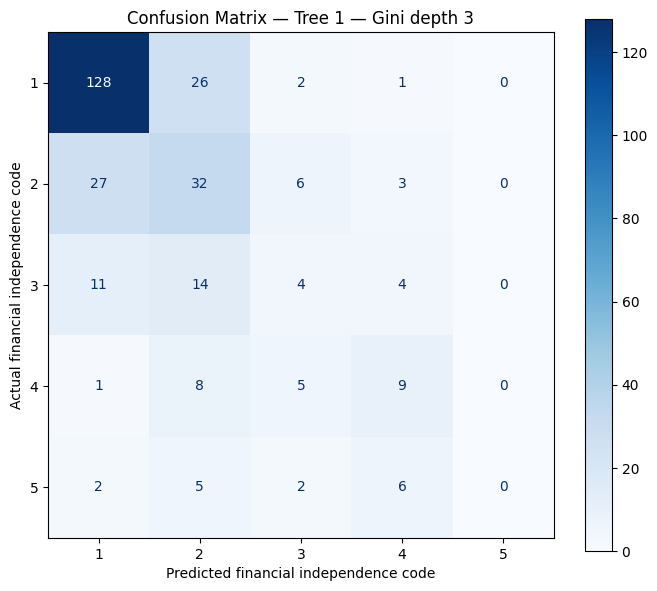

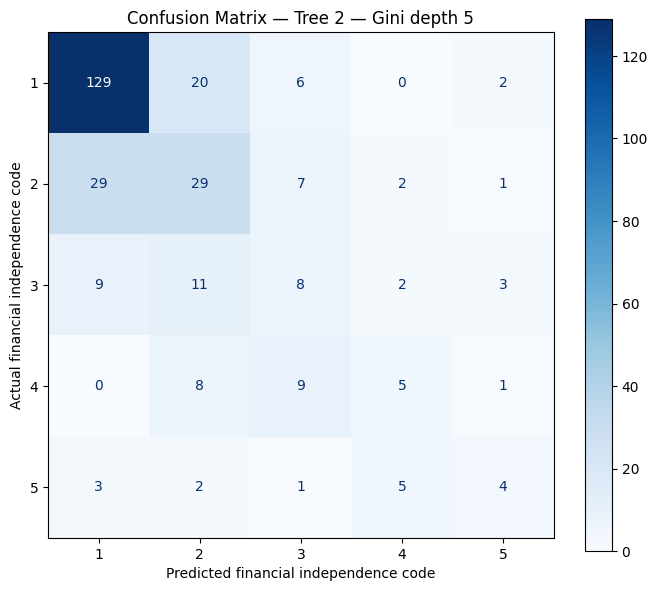

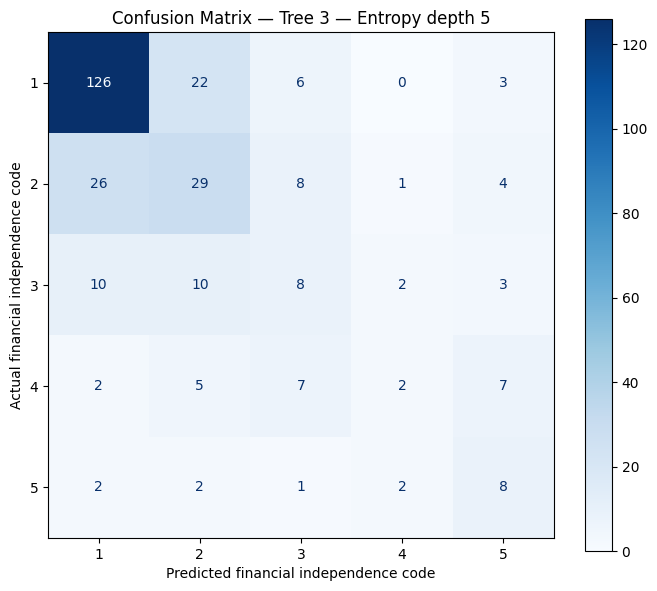

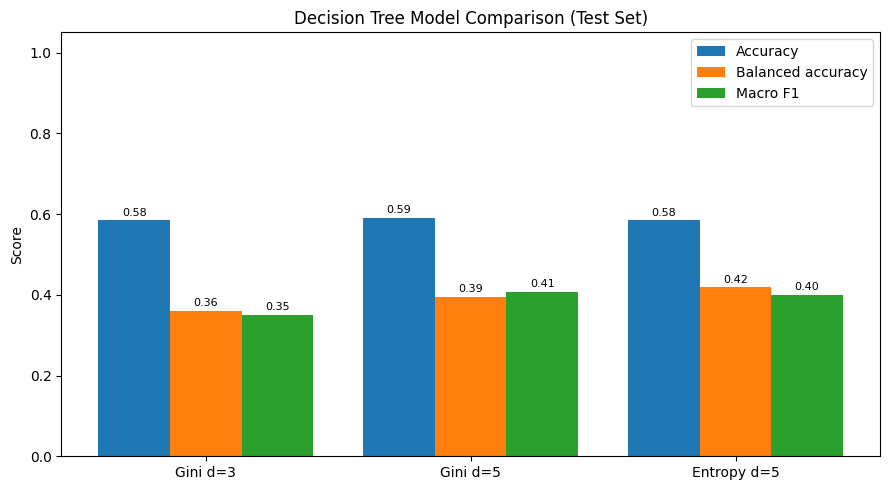

In [8]:
for number, (name, predicted) in enumerate(predictions.items(), start=1):
    fig, ax = plt.subplots(figsize=(7, 6))
    ConfusionMatrixDisplay.from_predictions(
        y_test, predicted, labels=class_labels, cmap="Blues",
        values_format="d", ax=ax, colorbar=True
    )
    ax.set_title(f"Confusion Matrix — {name}")
    ax.set_xlabel("Predicted financial independence code")
    ax.set_ylabel("Actual financial independence code")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"dt_confusion_matrix_{number}.png", dpi=190, bbox_inches="tight")
    plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(results))
w = 0.27
for j, metric in enumerate(["Accuracy", "Balanced accuracy", "Macro F1"]):
    bars = ax.bar(x + (j-1)*w, results[metric], w, label=metric)
    ax.bar_label(bars, fmt="%.2f", padding=2, fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(["Gini d=3", "Gini d=5", "Entropy d=5"])
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("Decision Tree Model Comparison (Test Set)")
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "dt_model_comparison.png", dpi=190, bbox_inches="tight")
plt.show()

## 8. Export predictions and highlight best-performing tree



Highest macro F1 among the three: Tree 2 — Gini depth 5
Test accuracy: 59.12%
Test macro F1: 0.407

Confusion matrix:
[[129  20   6   0   2]
 [ 29  29   7   2   1]
 [  9  11   8   2   3]
 [  0   8   9   5   1]
 [  3   2   1   5   4]]

Majority-class baseline test accuracy: 53.04%


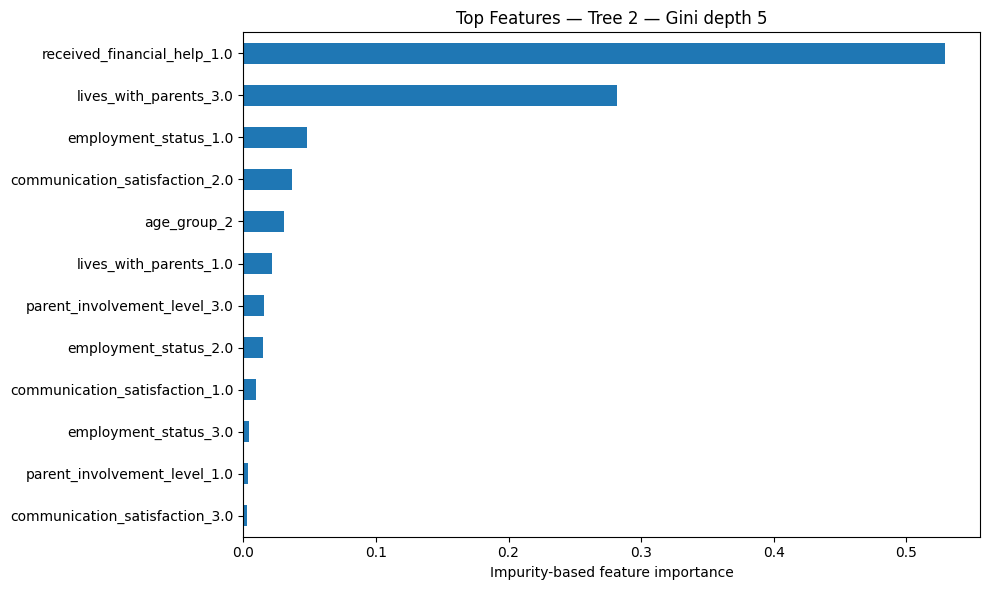

In [9]:
best_idx = results["Macro F1"].idxmax()
best_name = results.loc[best_idx, "Tree"]
best_pred = predictions[best_name]

prediction_df = pd.DataFrame({
    "source_row_index": X_test.index,
    "actual_financial_independence_code": y_test.to_numpy()
})
for name, pred in predictions.items():
    col = (name.lower().replace(" — ", "_").replace(" ", "_"))
    prediction_df[f"pred_{col}"] = pred
prediction_df.to_csv(OUTPUT_DIR / "dt_test_predictions.csv", index=False)

print("Highest macro F1 among the three:", best_name)
print("Test accuracy:", f"{accuracy_score(y_test, best_pred):.2%}")
print("Test macro F1:", f"{f1_score(y_test, best_pred, average='macro', zero_division=0):.3f}")
print("\nConfusion matrix:")
print(confusion_matrix(y_test, best_pred, labels=class_labels))
print("\nMajority-class baseline test accuracy:",
      f"{y_test.value_counts(normalize=True).max():.2%}")

# Save feature importance chart for one additional research visualization.
importances = pd.Series(models[best_name].feature_importances_, index=X_train_encoded.columns)
importances = importances.sort_values(ascending=False).head(12)
fig, ax = plt.subplots(figsize=(10, 6))
importances.sort_values().plot(kind="barh", ax=ax)
ax.set_xlabel("Impurity-based feature importance")
ax.set_title(f"Top Features — {best_name}")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "dt_feature_importance.png", dpi=180, bbox_inches="tight")
plt.show()

In [10]:
zip_path = Path("06_Decision_Tree_Outputs.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for file in sorted(OUTPUT_DIR.iterdir()):
        if file.is_file():
            zf.write(file, arcname=file.name)
print(f"Created {zip_path} with {len(list(OUTPUT_DIR.iterdir()))} files")
print("Files:")
for file in sorted(OUTPUT_DIR.iterdir()):
    print(" -", file.name)


Created 06_Decision_Tree_Outputs.zip with 17 files
Files:
 - dt_confusion_matrix_1.png
 - dt_confusion_matrix_2.png
 - dt_confusion_matrix_3.png
 - dt_feature_importance.png
 - dt_labeled_data.csv
 - dt_labeled_sample.png
 - dt_model_comparison.csv
 - dt_model_comparison.png
 - dt_test_predictions.csv
 - dt_testing_data.csv
 - dt_testing_sample.png
 - dt_train_test_split.png
 - dt_training_data.csv
 - dt_training_sample.png
 - dt_tree_1.png
 - dt_tree_2.png
 - dt_tree_3.png
